# Discount, Margin and the Central Gap

This notebook tests the report's main claim with a regression instead of a table: **does discounting explain Central's lower margin, even after controlling for the product (sub-category)?**

## Questions
1. At which discount level does the margin turn negative?
2. Central earns a lower margin than West. How much of that gap remains after controlling for sub-category, and after adding the discount?

## Method
- Margin is `profit / sales`, in percentage points. Models are **weighted by sales (WLS)**, so the coefficients describe the *dollar-weighted* margin, the same definition used in the report (`SUM(profit) / SUM(sales)`).
- Standard errors are heteroskedasticity-robust (HC3).
- West is the reference region, and 0% is the reference discount level.

> The dates in this dataset were shifted to 2023-2026; the timeline is simulated.

## 1. Load the cleaned data

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

DATA_PATH = "../data/processed/samplesuperstore_clean.csv"
df = pd.read_csv(DATA_PATH, dtype={"postal_code": "string"}, parse_dates=["order_date", "ship_date"])

# Compare with the SQL layer (01b_load_main.sql and 04_model_checks.sql, check 1)
print(f"Order lines: {len(df):,} | Sales: {df['sales'].sum():,.2f} | Profit: {df['profit'].sum():,.2f}")

Order lines: 10,192 | Sales: 2,326,153.86 | Profit: 292,273.46


## 2. Where does the margin turn negative?
Margin by exact discount level, over all order lines.

In [11]:
by_discount = (
    df.groupby("discount")
      .agg(order_lines=("row_id", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
      .assign(margin_pct=lambda t: t["profit"] / t["sales"] * 100)
)
by_discount.round({"sales": 0, "profit": 0, "margin_pct": 1})

,order_lines,sales,profit,margin_pct
discount,,,,
0.00,4924,1105225.0,326683.0,29.6
0.10,96,54952.0,9100.0,16.6
0.15,52,27559.0,1419.0,5.1
0.20,3706,773939.0,91080.0,11.8
0.30,229,104193.0,-10501.0,-10.1
0.32,27,14493.0,-2391.0,-16.5
0.40,207,116498.0,-23086.0,-19.8
0.45,11,5485.0,-2493.0,-45.5
0.50,66,58919.0,-20506.0,-34.8


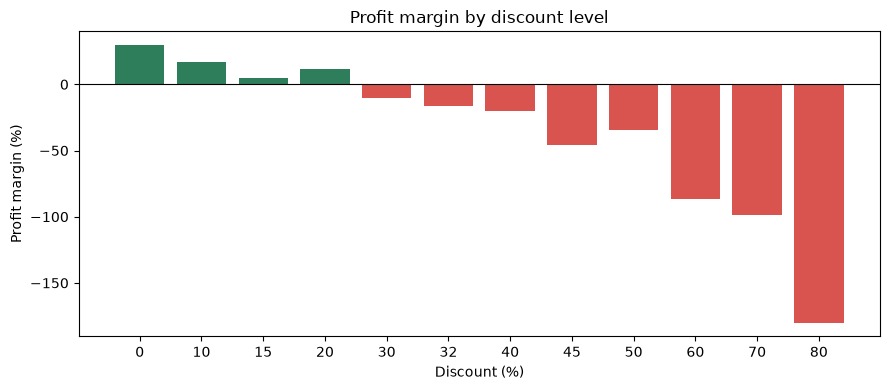

First discount level with a negative margin: 30%


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = np.where(by_discount["margin_pct"] < 0, "#d9534f", "#2e7d5b")
labels = np.round(by_discount.index * 100).astype(int).astype(str)
ax.bar(labels, by_discount["margin_pct"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Profit margin (%)")
ax.set_title("Profit margin by discount level")
plt.tight_layout()
plt.show()

negative = by_discount[by_discount["margin_pct"] < 0]
first_negative = f"{negative.index.min():.0%}" if len(negative) else "none"
print(f"First discount level with a negative margin: {first_negative}")

## 3. Does discounting explain Central's gap?
Four nested models, all weighted by sales:

| Model | Controls |
|---|---|
| A | Region only (reproduces the margins in the report) |
| B | A + sub-category |
| C | B + discount (linear, in percentage points) |
| D | B + discount bands (0%, 1-10%, 11-20%, >20%), to check that the linear form is not driving the result |

In [13]:
d = df[df["sales"] > 0].copy()
d["margin"] = d["profit"] / d["sales"] * 100       # percentage points
d["discount_pp"] = d["discount"] * 100              # percentage points
d["discount_band"] = pd.cut(
    d["discount"], bins=[-0.001, 0, 0.10, 0.20, 1.0], labels=["0%", "1-10%", "11-20%", ">20%"]
)

region_dummies = pd.get_dummies(d["region"], prefix="region", dtype=float).drop(columns="region_West")
subcat_dummies = pd.get_dummies(d["sub_category"], prefix="sub", drop_first=True, dtype=float)
band_dummies = pd.get_dummies(d["discount_band"], prefix="band", dtype=float).drop(columns="band_0%")

def fit_wls(*blocks):
    X = sm.add_constant(pd.concat(blocks, axis=1))
    return sm.WLS(d["margin"], X, weights=d["sales"]).fit(cov_type="HC3")

models = {
    "A. Region only":         fit_wls(region_dummies),
    "B. + sub-category":      fit_wls(region_dummies, subcat_dummies),
    "C. + discount (linear)": fit_wls(region_dummies, subcat_dummies, d[["discount_pp"]]),
    "D. + discount (bands)":  fit_wls(region_dummies, subcat_dummies, band_dummies),
}

# Sanity check: model A must reproduce the regional margins in the report
a = models["A. Region only"]
print(f"West margin (model A constant): {a.params['const']:.1f}%   [report: 15.0%]")
print(f"Central margin (constant + coefficient): {a.params['const'] + a.params['region_Central']:.1f}%   [report: 7.9%]")

West margin (model A constant): 15.0%   [report: 15.0%]
Central margin (constant + coefficient): 7.9%   [report: 7.9%]


In [14]:
rows = []
for name, res in models.items():
    ci = res.conf_int().loc["region_Central"]
    rows.append({
        "Model": name,
        "Central vs West (pp of margin)": res.params["region_Central"],
        "95% CI low": ci.iloc[0],
        "95% CI high": ci.iloc[1],
        "p-value": res.pvalues["region_Central"],
    })
central_gap = pd.DataFrame(rows).set_index("Model").round(2)
central_gap

,Central vs West (pp of margin),95% CI low,95% CI high,p-value
Model,,,,
A. Region only,-7.05,-12.48,-1.63,0.01
B. + sub-category,-7.93,-12.11,-3.74,0.00
C. + discount (linear),-3.91,-5.72,-2.10,0.00
D. + discount (bands),2.64,0.01,5.26,0.05


In [15]:
gap_a = models["A. Region only"].params["region_Central"]
gap_b = models["B. + sub-category"].params["region_Central"]
gap_c = models["C. + discount (linear)"].params["region_Central"]

print(f"Central vs West, region only:                  {gap_a:6.2f} pp")
print(f"... controlling for sub-category:              {gap_b:6.2f} pp  ({1 - gap_b / gap_a:+.0%} of the raw gap absorbed)")
print(f"... controlling for sub-category and discount: {gap_c:6.2f} pp  ({1 - gap_c / gap_a:+.0%} of the raw gap absorbed)")

c = models["C. + discount (linear)"]
ci = c.conf_int().loc["discount_pp"]
print(f"\nModel C: each +1 pp of discount changes the margin by {c.params['discount_pp']:.2f} pp "
      f"(95% CI {ci.iloc[0]:.2f} to {ci.iloc[1]:.2f})")

Central vs West, region only:                   -7.05 pp
... controlling for sub-category:               -7.93 pp  (-12% of the raw gap absorbed)
... controlling for sub-category and discount:  -3.91 pp  (+45% of the raw gap absorbed)

Model C: each +1 pp of discount changes the margin by -1.63 pp (95% CI -1.75 to -1.50)


In [16]:
region_cols = list(region_dummies.columns)
coefs = pd.DataFrame({name: res.params[region_cols] for name, res in models.items()}).round(2)
coefs.index = [i.replace("region_", "") + " vs West" for i in coefs.index]
coefs

,A. Region only,B. + sub-category,C. + discount (linear),D. + discount (bands)
Central vs West,-7.05,-7.93,-3.91,2.64
East vs West,-1.26,-1.77,-0.57,6.10
South vs West,-3.04,-1.57,-0.64,2.63


In [17]:
def fit_ols(*blocks):
    X = sm.add_constant(pd.concat(blocks, axis=1))
    return sm.OLS(d["margin"], X).fit(cov_type="HC3")

ols_models = {
    "A. Region only":         fit_ols(region_dummies),
    "B. + sub-category":      fit_ols(region_dummies, subcat_dummies),
    "C. + discount (linear)": fit_ols(region_dummies, subcat_dummies, d[["discount_pp"]]),
    "D. + discount (bands)":  fit_ols(region_dummies, subcat_dummies, band_dummies),
}
pd.DataFrame({k: v.params.filter(like="region_") for k, v in ols_models.items()}).round(2)

,A. Region only,B. + sub-category,C. + discount (linear),D. + discount (bands)
region_Central,-32.50,-32.00,-6.12,-5.84
region_East,-4.97,-4.81,1.77,7.69
region_South,-5.67,-6.10,1.69,1.80


## 4. Limitations
- **Association, not causation.** A discount lowers revenue while cost stays the same, so part of the margin-discount link is mechanical. The models show how much of Central's gap travels with the discount level, not *why* those discounts were granted.
- **Linear form.** Margin falls faster above 20% (section 2). Model D, with discount bands, checks that the Central estimate does not depend on the linear form.
- **Limited controls.** Only sub-category and discount are controlled for. Customer segment and ship mode are available and could be added.
- **Standard errors** are robust to heteroskedasticity but do not cluster by order, so lines in the same order are treated as independent.
- **Simulated dates** (2023-2026), and a sample dataset without operating costs.

## 5. Interpretation

**Central's gap is not a product-mix effect.** Central earns a margin 7.05 pp below West in dollar-weighted terms (model A), and 32.5 pp below on the average order line (unweighted, because small, deeply discounted lines carry extreme margins). Controlling for sub-category does not shrink the gap in either version (−7.93 pp weighted, model B), so Central's product mix does not explain it. For South, in contrast, sub-category absorbs about half of the raw gap (−3.04 to −1.57 pp).

**Discount absorbs most of the gap.** Each +1 pp of discount is associated with 1.63 pp less margin (95% CI −1.75 to −1.50; −1.99 pp unweighted). A linear discount term absorbs about 45% of the dollar-weighted gap (−3.91 pp, model C) and about 81% of the unweighted gap (−6.12 pp). With discount bands, which capture the sharp non-linear loss of margin at high discounts (section 2), Central is no longer below West in the dollar-weighted model (+2.64 pp, 95% CI 0.01 to 5.26, borderline), while the unweighted model keeps a residual of −5.84 pp. Whether discount explains all of the gap therefore depends on the weighting.

**West's advantage reflects lower discounting.** With discount bands, East (+6.10 pp) and South (+2.63 pp) end up above West in the dollar-weighted model, and the same holds unweighted (+7.69 and +1.80 pp).

**Where the discounts are.** The SQL analysis (`sql/07` and `sql/08`) shows that 18.9% of Central's order lines are discounted 60% or more, against 3.1% in West. Without those lines, Central's margin would be 15.9% against 16.8% in West. This matches the unweighted result: the lines that pull the average down are small and deeply discounted.

These results are associations, not causal effects: the models show how much of Central's gap travels with the discount level, not why those discounts were granted.